[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/16-careers/notebooks/01-resume-keyword-matcher.ipynb)

# 01 · Resume keyword matcher

Many companies first store and search applications in an **ATS** (Applicant Tracking System — software that lets recruiters filter resumes by keywords). In this notebook we build a small, honest version of that filter so you can check your own resume against a **JD** (job description).

**What you will learn**
1. Clean text and count words — and why raw word counts are noisy.
2. Match skills using a vocabulary with **synonyms** ("FAISS" counts as "vector database").
3. Measure overall similarity with **TF-IDF** and cosine similarity.
4. Find important JD phrases missing from your resume.
5. (Optional) match each JD requirement to your best resume bullet with sentence **embeddings**.

**Honesty rule:** only add a keyword to your resume if you really have the skill. Interviews will test it.

## Step 1 — load a sample resume and job description

The files live in `16-careers/data/`. The helper looks for them locally and downloads them in Colab. Replace them with your own text later (paste into the variables).

In [1]:
import pathlib, urllib.request

RAW = "https://raw.githubusercontent.com/vvvvvivekkk/AI-Engineer/main/16-careers/data/"

def data_path(name: str) -> pathlib.Path:
    """Find a data file locally (repo checkout) or download it (Colab)."""
    for p in [pathlib.Path("../data") / name, pathlib.Path("data") / name, pathlib.Path(name)]:
        if p.exists():
            return p
    target = pathlib.Path(name)
    urllib.request.urlretrieve(RAW + name, target)      # works in Colab once the repo is public
    return target
print("loader ready")

loader ready


Now read both files into Python strings and peek at the first lines.

In [2]:
resume = data_path("sample_resume.txt").read_text(encoding="utf-8")
jd = data_path("sample_job_description.txt").read_text(encoding="utf-8")
print(resume[:400], "...\n")
print(jd[:400], "...")

ANANYA RAO
Bengaluru, India | ananya.rao@example.com | linkedin.com/in/ananya-rao-example | github.com/ananya-rao-example

SUMMARY
Final-year computer science student building LLM applications. Built and deployed two RAG chatbots and a sentiment classifier.

SKILLS
Languages: Python, SQL, JavaScript
ML/AI: scikit-learn, PyTorch, Hugging Face transformers, sentence-transformers, embeddings
LLM tool ...

Junior AI Engineer (LLM Applications) - Example Tech, Remote

About the role
You will build and ship LLM-powered features used by thousands of customers: retrieval-augmented generation (RAG) over product documentation, AI agents that call internal tools, and the APIs that serve them.

What you will do
- Design and build RAG pipelines: chunking, embeddings, vector database, hybrid search and rerank ...


## Step 2 — normalise and split into words

**Normalising** text means making it uniform: lower-case, single spaces. Then a **regular expression** (a pattern for finding text) splits it into words. We keep characters like `/`, `+`, `-` inside words so "ci/cd" and "fine-tuning" survive.

In [3]:
import re
from collections import Counter

def normalise(text):
    return re.sub(r"\s+", " ", text.lower())

def words(text):
    return re.findall(r"[a-z][a-z0-9+/.-]*[a-z0-9]", normalise(text))

print(words("Build RAG pipelines with FAISS, CI/CD and fine-tuning (LoRA)."))

['build', 'rag', 'pipelines', 'with', 'faiss', 'ci/cd', 'and', 'fine-tuning', 'lora']


## Step 3 — naive overlap, and why it is misleading

Count the most common JD words and check which appear in the resume. Look at the top of the list: words like "and", "with", "you" dominate. These are **stop words** — very common words that carry little meaning.

In [4]:
jd_counts = Counter(words(jd))
resume_words = set(words(resume))
for w, c in jd_counts.most_common(12):
    print(f"{c:3d}  {w:15s} {'in resume' if w in resume_words else '-'}")

 13  and             in resume
 10  with            in resume
  4  apis            -
  4  experience      in resume
  3  llm             in resume
  3  build           -
  3  rag             in resume
  3  for             in resume
  2  ai              in resume
  2  applications    in resume
  2  the             in resume
  2  you             -


## Step 4 — remove stop words

scikit-learn ships a list of English stop words. Removing them leaves the words that describe the job.

In [5]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

jd_content = Counter(w for w in words(jd) if w not in ENGLISH_STOP_WORDS)
for w, c in jd_content.most_common(15):
    print(f"{c:3d}  {w:15s} {'in resume' if w in resume_words else 'MISSING'}")

  4  apis            MISSING
  4  experience      in resume
  3  llm             in resume
  3  build           MISSING
  3  rag             in resume
  2  ai              in resume
  2  applications    in resume
  2  features        MISSING
  2  product         MISSING
  2  documentation   MISSING
  2  agents          MISSING
  2  tools           in resume
  2  vector          MISSING
  2  database        MISSING
  2  actions         MISSING


## Step 5 — a skill vocabulary with synonyms

Single words still miss the point: the JD says "vector database", the resume says "FAISS" — the same skill. So we define **canonical skills** with the different ways people write them, and match whole words only (so "rag" does not match inside "storage").

In [6]:
SKILLS = {
    "python": ["python"], "sql": ["sql", "postgres", "mysql"], "git": ["git", "github"],
    "pytest / testing": ["pytest", "unit test", "unit testing", "tests"],
    "pytorch": ["pytorch", "torch"], "transformers / hugging face": ["hugging face", "transformers", "distilbert"],
    "llm apis": ["openai api", "anthropic", "llm api", "llm apis"],
    "prompt engineering": ["prompt engineering", "prompting"],
    "structured outputs": ["structured output", "structured outputs", "json schema"],
    "rag": ["rag", "retrieval-augmented", "retrieval augmented"],
    "embeddings": ["embedding", "embeddings", "sentence-transformers", "minilm"],
    "vector database": ["vector database", "faiss", "qdrant", "pgvector", "chroma"],
    "hybrid search / reranking": ["hybrid search", "bm25", "reranking", "reranker"],
    "agents / tool calling": ["agent", "agents", "tool calling", "function calling"],
    "langgraph": ["langgraph"], "fastapi / rest apis": ["fastapi", "rest api", "rest apis"],
    "docker": ["docker", "container"], "kubernetes": ["kubernetes"], "ci/cd": ["ci/cd", "github actions"],
    "cloud": ["aws", "gcp", "azure", "cloud"],
    "evaluation / evals": ["evaluation", "evals", "evaluated", "hit rate"],
    "observability": ["observability", "langfuse", "monitoring"],
    "guardrails / security": ["guardrails", "pii", "prompt injection", "red-teaming"],
    "fine-tuning": ["fine-tuning", "fine-tuned", "lora"],
    "streamlit / gradio": ["streamlit", "gradio"],
    "rubrics / annotation": ["rubric", "rubrics", "annotation", "rated and ranked"],
    "communication": ["communication", "documentation", "written english"],
}

def find_skills(text):
    t = normalise(text)
    return {name for name, variants in SKILLS.items()
            if any(re.search(r"(?<![a-z0-9])" + re.escape(v) + r"(?![a-z0-9])", t) for v in variants)}

jd_skills, cv_skills = find_skills(jd), find_skills(resume)
matched, missing = sorted(jd_skills & cv_skills), sorted(jd_skills - cv_skills)
print(f"Coverage: {len(matched)}/{len(jd_skills)} = {len(matched)/len(jd_skills):.0%}")
print("Matched:", matched)
print("Missing:", missing)

Coverage: 10/23 = 43%
Matched: ['embeddings', 'evaluation / evals', 'fine-tuning', 'git', 'llm apis', 'prompt engineering', 'python', 'rag', 'sql', 'vector database']
Missing: ['agents / tool calling', 'ci/cd', 'cloud', 'communication', 'docker', 'fastapi / rest apis', 'guardrails / security', 'hybrid search / reranking', 'kubernetes', 'langgraph', 'observability', 'pytest / testing', 'structured outputs']


## Step 6 — TF-IDF similarity

**TF-IDF** ("term frequency – inverse document frequency") gives each word a weight: high if it appears often in *this* text but is not common everywhere. Each text becomes a vector of weights. **Cosine similarity** measures how much two vectors point the same way (0 = nothing shared, 1 = identical word use).

The number on its own means little; use it to **compare versions** of your resume against the same JD.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))
m = vec.fit_transform([resume, jd])
print(f"TF-IDF cosine similarity: {cosine_similarity(m[0], m[1])[0, 0]:.3f}")

terms = vec.get_feature_names_out()
jd_weights = m[1].toarray()[0]
top = jd_weights.argsort()[::-1][:12]
print("Most important JD terms:", [terms[i] for i in top])

TF-IDF cosine similarity: 0.096
Most important JD terms: ['apis', 'build', 'experience', 'llm', 'rag', 'similar', 'database', 'features', 'docker', 'evaluation', 'agents', 'documentation']


## Step 7 — frequent JD phrases missing from the resume

Two-word phrases ("vector database", "human-in-the-loop approval") often carry more meaning than single words. We count 1- and 2-word phrases in the JD and list the frequent ones that never appear in the resume.

In [8]:
def missing_phrases(resume, jd, top=12):
    ws = [w for w in words(jd) if w not in ENGLISH_STOP_WORDS]
    grams = ws + [" ".join(p) for p in zip(ws, ws[1:])]
    r = normalise(resume)
    return [(g, c) for g, c in Counter(grams).most_common() if g not in r][:top]

for phrase, n in missing_phrases(resume, jd):
    print(f"{n}x  {phrase}")

4x  apis
2x  features
2x  product
2x  documentation
2x  agents
2x  vector
2x  database
2x  actions
2x  docker
2x  evaluation
2x  similar
2x  vector database


## Step 8 — visualise matched vs missing skills

A quick chart makes the gap obvious — useful when coaching students one-to-one.

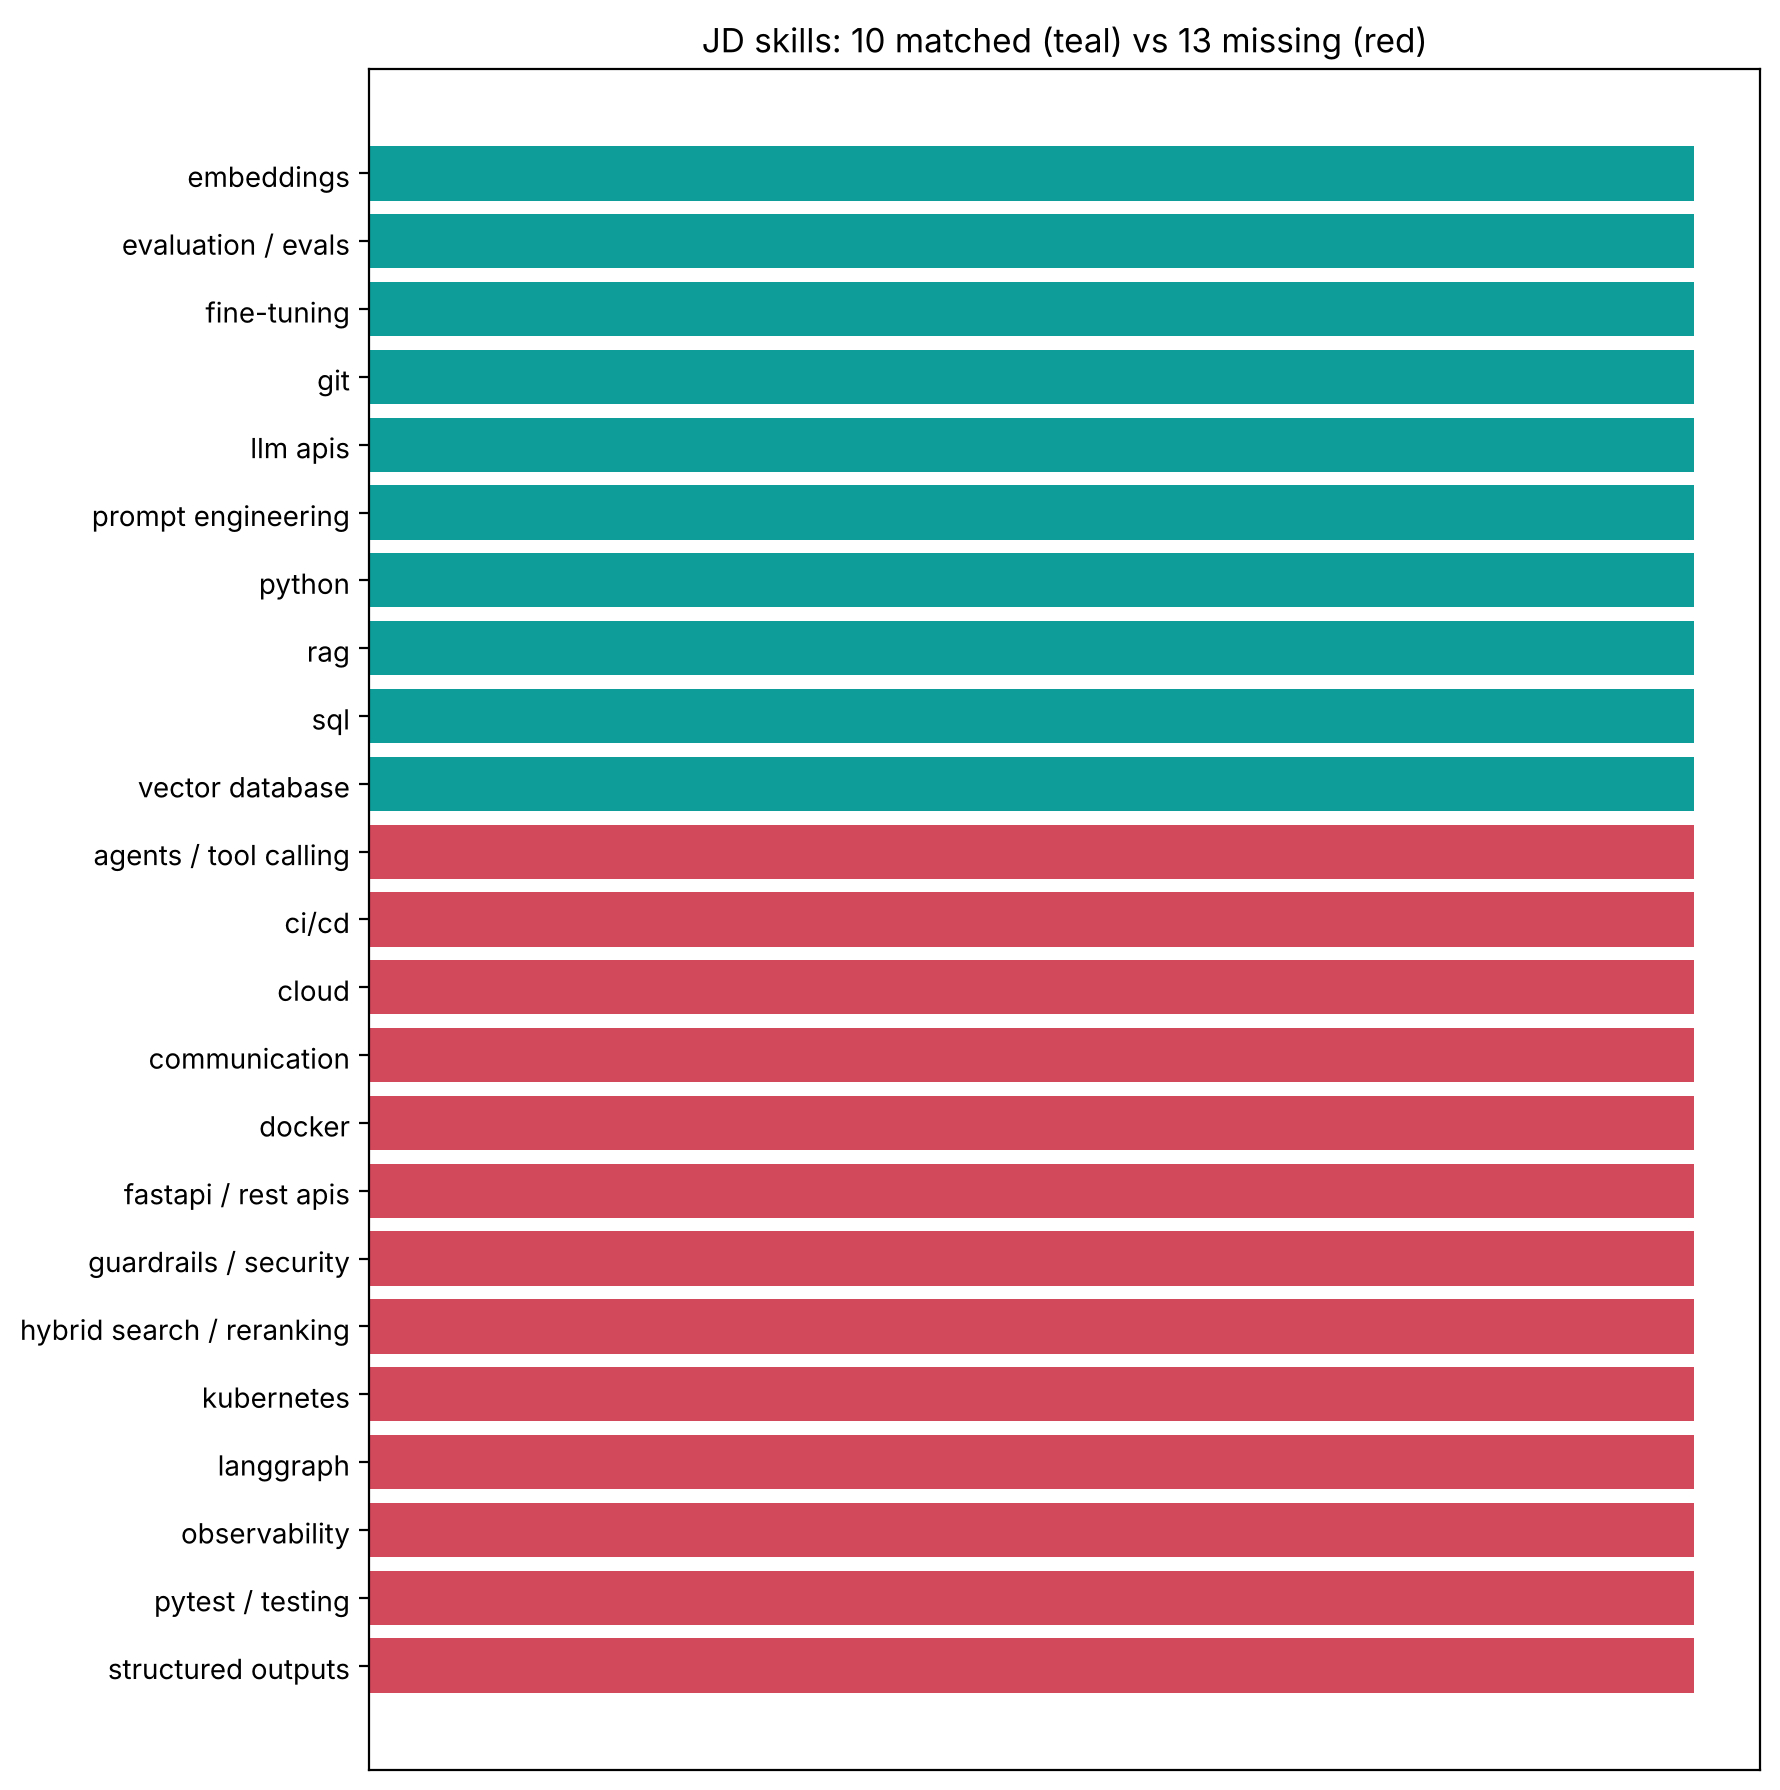

In [9]:
import matplotlib.pyplot as plt
labels = matched + missing
colors = ["#0f9d9a"] * len(matched) + ["#d1495b"] * len(missing)
plt.figure(figsize=(9, 0.35 * len(labels) + 1))
plt.barh(labels, [1] * len(labels), color=colors)
plt.xticks([]); plt.gca().invert_yaxis()
plt.title(f"JD skills: {len(matched)} matched (teal) vs {len(missing)} missing (red)")
plt.tight_layout(); plt.show()

## Step 9 — an honest improvement

Suppose the candidate *really did* use FastAPI, Docker and pytest in the Campus Policy Assistant but forgot to say so, and *really did* write the evaluation set. We add one truthful bullet and re-score. (Never add skills you do not have.)

In [10]:
resume_v2 = resume.replace(
    "- Deployed a Streamlit demo used by 120 students in the first week.",
    "- Deployed a Streamlit demo used by 120 students in the first week.\n"
    "- Served the retriever through a FastAPI REST API packaged with Docker; added pytest tests run by GitHub Actions CI/CD.")

def score(cv):
    s = find_skills(cv) & jd_skills
    m = TfidfVectorizer(stop_words="english", ngram_range=(1, 2)).fit_transform([cv, jd])
    return len(s) / len(jd_skills), cosine_similarity(m[0], m[1])[0, 0]

for name, cv in [("v1", resume), ("v2", resume_v2)]:
    cov, sim = score(cv)
    print(f"{name}: skill coverage {cov:.0%}, TF-IDF similarity {sim:.3f}")
print("Still missing:", sorted(jd_skills - find_skills(resume_v2)))

v1: skill coverage 43%, TF-IDF similarity 0.096
v2: skill coverage 61%, TF-IDF similarity 0.114
Still missing: ['agents / tool calling', 'cloud', 'communication', 'guardrails / security', 'hybrid search / reranking', 'kubernetes', 'langgraph', 'observability', 'structured outputs']


## Step 10 — which role fits this resume better?

Run the same resume against a second JD — a freelance **AI trainer (Python coding)** role. Comparing coverage across JDs helps choose where to apply first.

In [11]:
jd_trainer = data_path("jd_ai_trainer.txt").read_text(encoding="utf-8")
for name, text in [("Junior AI Engineer", jd), ("AI Trainer - Python", jd_trainer)]:
    need = find_skills(text)
    have = need & cv_skills
    print(f"{name:22s} coverage {len(have)}/{len(need)} = {len(have)/len(need):.0%}   missing: {sorted(need - have)}")

Junior AI Engineer     coverage 10/23 = 43%   missing: ['agents / tool calling', 'ci/cd', 'cloud', 'communication', 'docker', 'fastapi / rest apis', 'guardrails / security', 'hybrid search / reranking', 'kubernetes', 'langgraph', 'observability', 'pytest / testing', 'structured outputs']
AI Trainer - Python    coverage 2/5 = 40%   missing: ['communication', 'guardrails / security', 'pytest / testing']


## Step 11 (optional) — match each requirement to your best bullet with embeddings

Keywords miss meaning: "evaluation datasets" and "hand-written questions" are related but share no words. **Sentence embeddings** turn each sentence into a vector so that similar meanings are close. We use the small `all-MiniLM-L6-v2` model (downloads ~90 MB from Hugging Face once). If it cannot load, the cell skips politely.

In [12]:
reqs = [l.strip("- ").strip() for l in jd.splitlines() if l.strip().startswith("- ")]
bullets = [l.strip("- ").strip() for l in resume.splitlines() if l.strip().startswith("- ")]
try:
    from sentence_transformers import SentenceTransformer, util
    model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
    sims = util.cos_sim(model.encode(reqs), model.encode(bullets))
    for i, r in enumerate(reqs):
        j = int(sims[i].argmax())
        flag = "weak - add evidence?" if sims[i, j] < 0.35 else ""
        print(f"{float(sims[i, j]):.2f} | REQ: {r[:70]}\n     | BEST: {bullets[j][:70]} {flag}\n")
except Exception as e:
    print("Embedding model unavailable, skipping:", type(e).__name__)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 39025.59it/s]

0.42 | REQ: Design and build RAG pipelines: chunking, embeddings, vector database,
     | BEST: Evaluated retrieval on 50 hand-written questions; improved hit rate fr 

0.23 | REQ: Build agents with tool calling using LangGraph, with human-in-the-loop
     | BEST: Built a retrieval-augmented chatbot over 800 pages of university regul weak - add evidence?

0.18 | REQ: Expose features through Python APIs built with FastAPI, packaged with 
     | BEST: Built a retrieval-augmented chatbot over 800 pages of university regul weak - add evidence?

0.27 | REQ: Create evaluation datasets and automated evals; track quality, latency
     | BEST: Fine-tuned DistilBERT on 25,000 reviews reaching 91% accuracy on the t weak - add evidence?

0.25 | REQ: Add guardrails: input validation, PII redaction and prompt injection d
     | BEST: Built a retrieval-augmented chatbot over 800 pages of university regul weak - add evidence?

0.28 | REQ: Collaborate with product managers and write clear documentation

## Recap

- Raw word counts are noisy; remove stop words and match **skills with synonyms**.
- TF-IDF similarity is for comparing *versions* of your resume against one JD, not an absolute grade.
- Missing-phrase lists and requirement-to-bullet matching show where to add **truthful** evidence.
- The same code lives in `code/resume_matcher.py`: `python code/resume_matcher.py my_resume.txt jd.txt`.

**Try it yourself:** paste your own resume and a real JD you want, list the top three truthful additions, and re-score.